In [40]:
import pandas as pd

In [41]:
df = pd.read_csv("https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv")


In [42]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [43]:
df['Class'].value_counts(normalize=True) #normalize transforma em %

,proportion
Class,
0,0.998273
1,0.001727


In [44]:
import numpy as np

df["Amount_log"] = np.log1p(df["Amount"])

In [45]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df["Amount_scaled"] = scaler.fit_transform(df[["Amount"]])

In [46]:
from sklearn.model_selection import train_test_split

X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, test_size=0.3, random_state=42
)

In [47]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [48]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.84      0.66      0.73       148

    accuracy                           1.00     85443
   macro avg       0.92      0.83      0.87     85443
weighted avg       1.00      1.00      1.00     85443



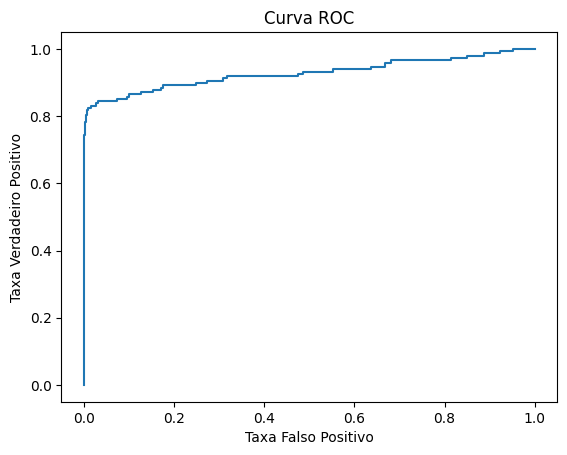

AUC:  0.9272042339543365


In [49]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_probs =model.predict_proba(X_test)[:,1]

fpr, tpr, _ = roc_curve(y_test, y_probs)

plt.plot(fpr, tpr)
plt.title("Curva ROC")
plt.xlabel("Taxa Falso Positivo")
plt.ylabel("Taxa Verdadeiro Positivo")
plt.show()

print("AUC: ", roc_auc_score(y_test, y_probs))

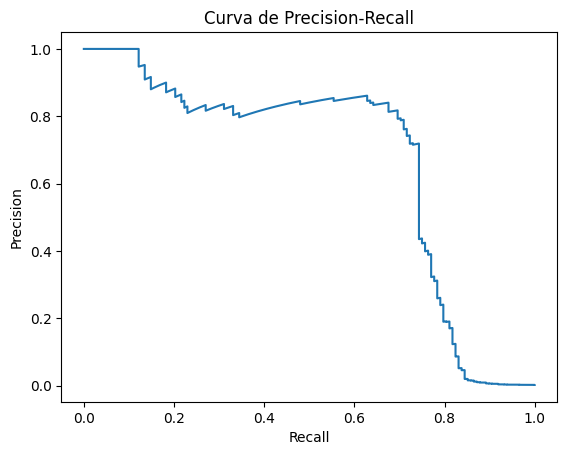

In [50]:
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(y_test, y_probs)

plt.plot(recall, precision)
plt.title("Curva de Precision-Recall")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

In [51]:
fraudes = df[df["Class"] ==1]
normais = df[df["Class"] ==0].sample(len(fraudes), random_state=42)

df_under = pd.concat([fraudes, normais])

In [52]:
from imblearn.over_sampling import SMOTE

smote = SMOTE()

X_res, y_res = smote.fit_resample(X, y)

In [53]:
from sklearn.ensemble import RandomForestClassifier

In [54]:
#Usando o pipeline
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ("scaler: ", StandardScaler()),
    ("model: ", LogisticRegression(max_iter=1000))
])

pipeline.fit(X_train, y_train)

y_pred_pipe = pipeline.predict(X_test)
y_pred_pipe

array([0, 0, 0, ..., 0, 0, 0])

In [55]:
threshold = 0.3

y_pred_custom = (y_probs > threshold).astype(int)

print(classification_report(y_test, y_pred_custom))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.79      0.71      0.75       148

    accuracy                           1.00     85443
   macro avg       0.89      0.85      0.87     85443
weighted avg       1.00      1.00      1.00     85443



In [56]:
#comparando com a Random Forest
rf = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.84      0.76      0.79       148

    accuracy                           1.00     85443
   macro avg       0.92      0.88      0.90     85443
weighted avg       1.00      1.00      1.00     85443



In [57]:
#comparando com a Xgboost
from xgboost import XGBClassifier

xgb = XGBClassifier(
scale_pos_weight=10, # ajuda com desbalanceamento
use_label_encoder=False,
eval_metric="logloss"
)

xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [20:48:00] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [58]:
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.94      0.78      0.85       148

    accuracy                           1.00     85443
   macro avg       0.97      0.89      0.93     85443
weighted avg       1.00      1.00      1.00     85443

